<a href="https://colab.research.google.com/github/imranAsyraf/Assignment-1-Data-Profiling/blob/main/Assignment_1_Data_Profiling_(EDA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data Engineering: Assignment 1 Data Profiling (EDA)**

Group Members:
1. Emmy Natasha binti Rosmani (A211993)
2. Nur Najwa Balqis binti Sulaiman (A212324)
3. Hannah binti Mohd Rose Rizal (A212377)
4. Wan Imran Asyraf Bin Wan Abdul Manan (A212326)

## **Part 1: Scenario**

A corporate Human Resources (HR) department is assessing the quality of a
synthetic employee dataset before using it for workforce reporting and
salary-data audits. The records contain missing age and salary values, a
combined department-region field, implausible negative phone numbers, and
personal identifiers, making the dataset suitable for investigating data
quality and privacy risks. This study aims to identify incomplete or
anomalous values, examine whether missingness differs across employment
statuses, and determine appropriate handling methods that preserve useful
records without introducing fabricated employee information.



## **Part 2: Data Source**

The Messy Employee Dataset was published by Kaggle contributor desolution01. This publicly available synthetic dataset simulates corporate Human Resources (HR) records with intentionally introduced data-quality issues and does not represent verified records of real employees. The dataset was obtained by manually downloading the Messy_Employee_dataset.csv file from Kaggle and importing it into a Jupyter Notebook using Python's Pandas library for data profiling and cleaning.

Dataset URL: https://www.kaggle.com/datasets/desolution01/messy-employee-dataset

### **2.1 Instructions to Run**

To reproduce the data profiling and cleaning process, follow these steps:

1. **Install the required libraries:** Ensure Python 3 and the pandas, numpy, matplotlib, and seaborn libraries are installed, or use a Jupyter Notebook environment with these dependencies available.

2. **Download the dataset:** Download Messy_Employee_dataset.csv from the Kaggle dataset URL provided above.

3. **Set up the dataset:** Place the CSV file in the same working directory as the Jupyter Notebook. If using Google Colab, upload the CSV file to the runtime's working directory.

4. **Execute the notebook:** Open the notebook in Jupyter and select Restart Kernel and Run All Cells to execute the code sequentially from beginning to end.

For the final GitHub submission, the dataset may be included in the repository if its redistribution license permits. Otherwise, the download URL and these instructions should be provided to ensure reproducibility.

### **2.2 Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **2.3 Load the Dataset**

In [2]:
from pathlib import Path

# Specify the dataset file
file_path = Path("Messy_Employee_dataset.csv")

# Check whether the dataset exists
if not file_path.is_file():
    raise FileNotFoundError("Dataset not found. Please check the file location.")

# Load the original dataset
df_raw = pd.read_csv(
    file_path,
    na_values=["", "N/A"],
    dtype={
        "Employee_ID": "string",
        "Phone": "string"
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### **2.4 Verify the Dataset**

In [3]:
# Display dataset dimensions
print("Dataset Shape:", df_raw.shape)

# Display column names
print("\nColumn Names:")
print(df_raw.columns.tolist())

Dataset Shape: (1020, 12)

Column Names:
['Employee_ID', 'First_Name', 'Last_Name', 'Age', 'Department_Region', 'Status', 'Join_Date', 'Salary', 'Email', 'Phone', 'Performance_Score', 'Remote_Work']


## **Part 3: Initial Data Profiling**

### **3.1 Dataset Overview**

In [4]:
# Show a sample of non-contact data without exposing PII-like fields.
preview_cols = [
    "Age", "Department_Region", "Status",
    "Join_Date", "Salary", "Performance_Score", "Remote_Work"
]
display(df_raw[preview_cols].head())

,Age,Department_Region,Status,Join_Date,Salary,Performance_Score,Remote_Work
0,25.0,DevOps-California,Active,4/2/2021,59767.65,Average,True
1,NaN,Finance-Texas,Active,7/10/2020,65304.66,Excellent,True
2,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,Good,True
3,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,Good,True
4,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,Poor,False


### **3.2 Examine Data Types and Non-Null Values**

In [5]:
# Display dataset information
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   string 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   string 
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), object(7), string(2)
memory usage: 88.8+ KB


### **3.3 Descriptive Statistics**

In [6]:
# Generate descriptive statistics for numerical columns
df_raw[["Age", "Salary"]].describe().round(2)

,Age,Salary
count,809.00,996.00
mean,32.48,85155.06
std,5.66,19873.73
min,25.00,50047.32
25%,25.00,68392.49
50%,30.00,85547.87
75%,40.00,100974.03
max,40.00,119971.65


### **3.4 Column-Level Profiling Summary**

In [7]:
# Create a profiling summary for every column
profile_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Non-Null Count": df_raw.notna().sum(),
    "Missing Count": df_raw.isna().sum(),
    "Missing (%)": (df_raw.isna().mean() * 100).round(2),
    "Unique Values": df_raw.nunique(dropna=True)
})

# Display the profiling summary
display(profile_summary)

,Data Type,Non-Null Count,Missing Count,Missing (%),Unique Values
Employee_ID,string,1020,0,0.00,1020
First_Name,object,1020,0,0.00,8
Last_Name,object,1020,0,0.00,8
Age,float64,809,211,20.69,4
Department_Region,object,1020,0,0.00,36
Status,object,1020,0,0.00,3
Join_Date,object,1020,0,0.00,760
Salary,float64,996,24,2.35,978
Email,object,1020,0,0.00,64
Phone,string,1020,0,0.00,1020


### **3.5 Interpretation of Initial Data Profiling**

The initial data profiling reveals that the dataset consists of 1,020 employee records and 12 attributes. Based on the non-null counts, the Age and Salary columns contain missing values, with only 809 and 996 validly populated entries, respectively, while the remaining columns have no detected missing entries. Descriptive statistical analysis shows that the observed employee ages range from 25 to 40 years, with a median of 30 years, whereas salaries range from 50,047.32 to 119,971.65, with a median of 85,547.87. Additionally, the Join_Date column is stored as an object data type, indicating the need for further date-format validation. These findings highlight the importance of examining data completeness, consistency and validity before proceeding with data cleaning and subsequent analysis.

## **Part 4: Missing-Value Diagnosis and Handling**

### **4.1 Identify Missing Values**

In [8]:
# Calculate missing values for each column
missing_count = df_raw.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (df_raw.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Sort from highest to lowest missing count
missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage (%)
Age,211,20.69
Salary,24,2.35
First_Name,0,0.00
Employee_ID,0,0.00
Last_Name,0,0.00
Department_Region,0,0.00
Status,0,0.00
Join_Date,0,0.00
Email,0,0.00
Phone,0,0.00


### **4.1.1 Examine Original Missing-Value Markers**

In [9]:
# Read original CSV as text to inspect missing-value markers
raw_text = pd.read_csv(
    file_path,
    dtype="string",
    keep_default_na=False,
    na_filter=False
)

# Count missing-value representations
age_blank = raw_text["Age"].str.strip().eq("").sum()

salary_na = (
    raw_text["Salary"]
    .str.strip()
    .str.upper()
    .eq("N/A")
    .sum()
)

print("Blank values in Age:", age_blank)
print("N/A values in Salary:", salary_na)

Blank values in Age: 211
N/A values in Salary: 24


### **4.2 Examine Incomplete Records**

In [10]:
# Count rows containing at least one missing value
incomplete_rows = df_raw.isnull().any(axis=1).sum()

# Count rows without any missing values
complete_rows = df_raw.notnull().all(axis=1).sum()

# Count rows missing both Age and Salary
missing_both = df_raw[["Age", "Salary"]].isnull().all(axis=1).sum()

print("Total Records:", len(df_raw))
print("Complete Records:", complete_rows)
print("Incomplete Records:", incomplete_rows)
print("Missing Both Age and Salary:", missing_both)

Total Records: 1020
Complete Records: 787
Incomplete Records: 233
Missing Both Age and Salary: 2


### **4.3 Visualize Missing Values**

**Chart 1: Missing-Value Heatmap**

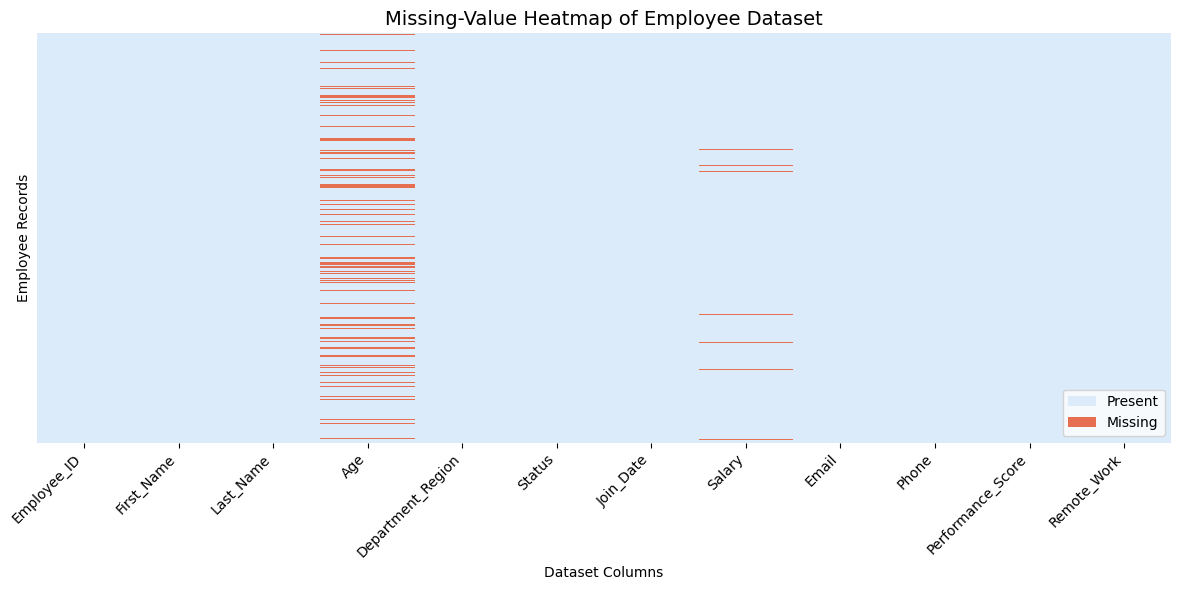

In [11]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Create missing-value heatmap
plt.figure(figsize=(12, 6))

cmap = ListedColormap(["#DCEBFA", "#E76F51"])

ax = sns.heatmap(
    df_raw.isnull(),
    cmap=cmap,
    vmin=0,
    vmax=1,
    cbar=False,
    yticklabels=False
)

plt.title(
    "Missing-Value Heatmap of Employee Dataset",
    fontsize=14
)

plt.xlabel("Dataset Columns")
plt.ylabel("Employee Records")

plt.xticks(rotation=45, ha="right")

ax.legend(
    handles=[
        Patch(facecolor="#DCEBFA", label="Present"),
        Patch(facecolor="#E76F51", label="Missing")
    ],
    loc="lower right"
)

plt.tight_layout()
plt.show()

**Heatmap interpretation:**

The orange cells occur only in Age and Salary, with substantially more missing entries in Age.

**Chart 2: Missing-Value Percentage Bar Chart**

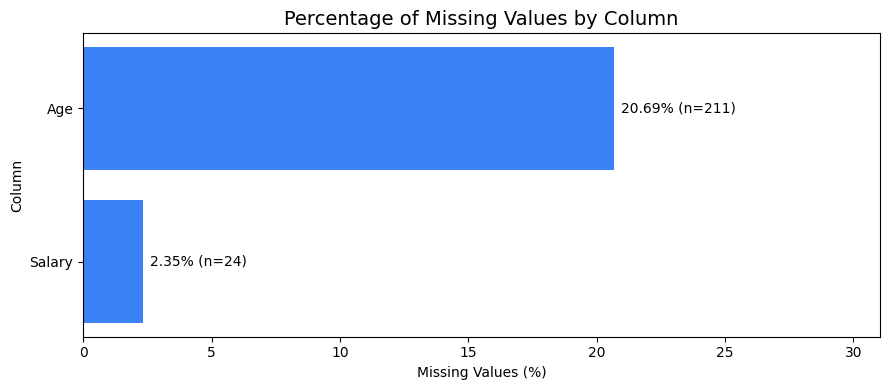

In [12]:
# Select columns with missing values
missing_data = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage (%)")

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    missing_data.index,
    missing_data["Missing Percentage (%)"],
    color="#3B82F6"
)

# Add exact values to bars
labels = [
    f"{pct:.2f}% (n={count})"
    for pct, count in zip(
        missing_data["Missing Percentage (%)"],
        missing_data["Missing Count"]
    )
]

ax.bar_label(bars, labels=labels, padding=5)

ax.set_xlim(
    0,
    missing_data["Missing Percentage (%)"].max() * 1.5
)

ax.set_title(
    "Percentage of Missing Values by Column",
    fontsize=14
)

ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Column")

plt.tight_layout()
plt.show()

**Bar-chart interpretation:**

Age is missing for 20.69% of employees (211 records), compared with 2.35% for Salary (24 records). The labels distinguish percentages from counts.

### **4.4 Examine Missingness across Employee Groups**

In [13]:
# Calculate missing-value rates by employment status
missing_by_status = df_raw.groupby("Status").agg(
    Total_Records=("Employee_ID", "size"),
    Age_Missing_Pct=(
        "Age",
        lambda x: x.isnull().mean() * 100
    ),
    Salary_Missing_Pct=(
        "Salary",
        lambda x: x.isnull().mean() * 100
    )
).round(2)

display(missing_by_status)

,Total_Records,Age_Missing_Pct,Salary_Missing_Pct
Status,,,
Active,352,22.44,2.56
Inactive,312,18.91,3.85
Pending,356,20.51,0.84


**Status-specific interpretation:**

Age missingness is highest for
Active employees (22.44%) and lowest for Inactive employees
(18.91%). Salary missingness is highest for Inactive employees (3.85%) and lowest for Pending employees (0.84%). The denominator is the number of records within each status group. These descriptive differences do not prove a causal or random mechanism.

### **4.5 Handle Missing Values**

In [14]:
# Create a separate working DataFrame
df_clean = df_raw.copy()

# Add missing-value indicator columns
df_clean["Age_missing_flag"] = df_clean["Age"].isnull()

df_clean["Salary_missing_flag"] = df_clean["Salary"].isnull()

# Check flagged records
print("Missing Age Flags:",
      df_clean["Age_missing_flag"].sum())

print("Missing Salary Flags:",
      df_clean["Salary_missing_flag"].sum())

Missing Age Flags: 211
Missing Salary Flags: 24


### **4.6 Verify the Handling Decisions**

In [15]:
# Confirm that no records were lost and original values were preserved.
print("Original Rows:", len(df_raw))
print("Rows After Handling:", len(df_clean))
assert len(df_clean) == len(df_raw)

tracked = ["Age", "Salary"]
for column in tracked:
    assert df_clean[f"{column}_missing_flag"].equals(df_raw[column].isna())

# This check also catches accidental changes to any original column.
pd.testing.assert_frame_equal(df_clean[df_raw.columns], df_raw)

# All figures are computed from the data; no missing counts hardcoded.
verification = pd.DataFrame({
    "Column": tracked,
    "Original Missing": df_raw[tracked].isna().sum().to_numpy(),
    "Flagged Records": [
        int(df_clean[f"{col}_missing_flag"].sum()) for col in tracked
    ],
    "Remaining Missing": df_clean[tracked].isna().sum().to_numpy(),
})
display(verification)

Original Rows: 1020
Rows After Handling: 1020


,Column,Original Missing,Flagged Records,Remaining Missing
0,Age,211,211,211
1,Salary,24,24,24


### **4.7 Interpretation and Justification**

Missing-value profiling identified two affected fields: Age has
211 missing entries (20.69%) and Salary has 24 (2.35%).
Original CSV inspection shows that Age uses blank cells, whereas
Salary uses the literal marker N/A. In total, 233 employees
(22.84%) have at least one missing field; two of these are missing
both Age and Salary.

The heatmap locates missing records, while the bar chart quantifies
the higher prevalence of missingness in Age. By employment status,
Age missingness ranges from 18.91% (Inactive) to 22.44%
(Active), whereas Salary missingness ranges from 0.84% (Pending)
to 3.85% (Inactive). These comparisons describe each status
group's own records and do not establish why the values are
missing or whether the missingness mechanism is random.

We used flag-and-retain handling for both fields. Deleting all
incomplete records would lose 233 employees, and imputing ages
could distort demographic statistics. Imputing unverified salaries
could also distort compensation distributions. Instead,
Age_missing_flag and Salary_missing_flag identify unknown values
without inventing information or deleting otherwise useful records.

After handling, all 1,020 original records remain. The missing
values are intentionally unresolved, so later age- or
salary-specific analyses must use observed values only, explicitly
report their sample sizes (Age: 809; Salary: 996), and flag cases
requiring verification from authoritative HR records.

## **Part 5: Outliers & Data Validation**

In this section, we focus on identifying numerical columns, detecting statistical outliers using the Interquartile Range (IQR) method, visualizing outliers through boxplots, determining an appropriate handling strategy with clear justifications, and validating the numerical fields for invalid values or inconsistent data types.

In [16]:
# 1. Identify numerical columns
numerical_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
print("Numerical Columns Identified:", numerical_cols)

# 2. Detect outliers using the IQR Method
outlier_summary = {}
for col in numerical_cols:
    # Temporarily drop missing values to perform accurate calculations
    non_null_series = df_clean[col].dropna()

    Q1 = non_null_series.quantile(0.25)
    Q3 = non_null_series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = non_null_series[(non_null_series < lower_bound) | (non_null_series > upper_bound)]

    outlier_summary[col] = {
        "Q1 (25th Percentile)": round(Q1, 2),
        "Q3 (75th Percentile)": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Detected Outliers": outliers.tolist()
    }

# Display the detailed outlier summary
display(pd.DataFrame(outlier_summary).T)

Numerical Columns Identified: ['Age', 'Salary']


,Q1 (25th Percentile),Q3 (75th Percentile),IQR,Lower Bound,Upper Bound,Outlier Count,Detected Outliers
Age,25.0,40.0,15.0,2.5,62.5,0,[]
Salary,68392.49,100974.03,32581.54,19520.18,149846.34,0,[]


### **5.1 Visualize Outliers Using Boxplots**
We will now construct boxplots for `Age` and `Salary` to inspect the distribution shape and visually confirm the presence of any extreme values or anomalies.

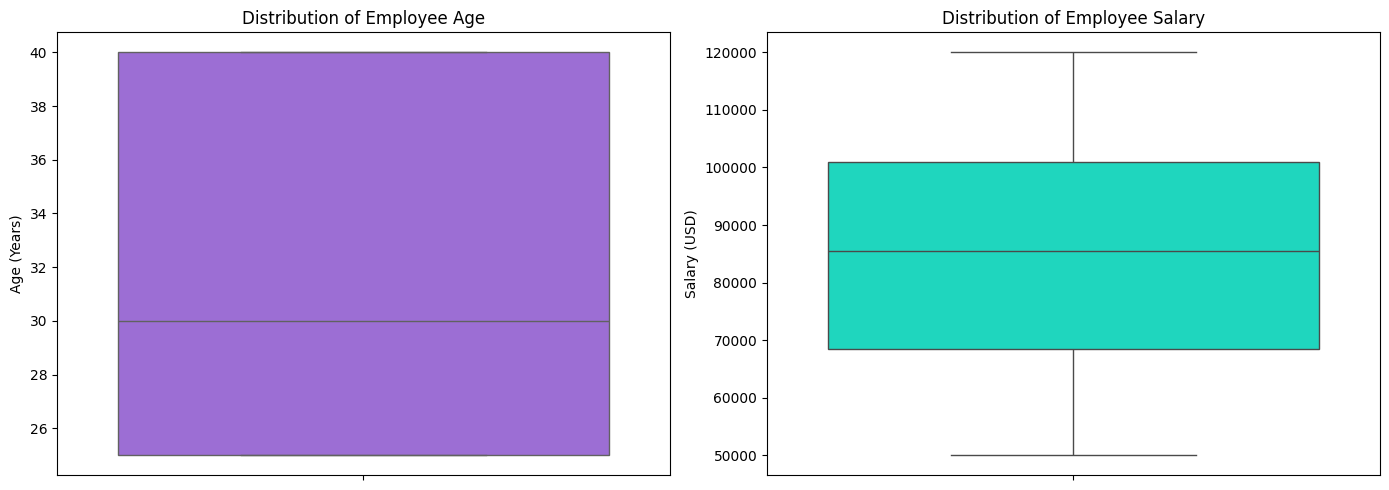

In [17]:
# 3. Create boxplots for visual confirmation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot for Age
sns.boxplot(data=df_clean, y="Age", ax=axes[0], color="#9B5DE5")
axes[0].set_title("Distribution of Employee Age", fontsize=12)
axes[0].set_ylabel("Age (Years)")

# Boxplot for Salary
sns.boxplot(data=df_clean, y="Salary", ax=axes[1], color="#00F5D4")
axes[1].set_title("Distribution of Employee Salary", fontsize=12)
axes[1].set_ylabel("Salary (USD)")

plt.tight_layout()
plt.show()

### **5.2 Outlier Decisions & Justification**
- **Analysis**: Both the IQR computations and boxplots show **0 outliers** for both Age and Salary. The observed Age records fall entirely within the standard range [25, 40], and the Salary records are normally distributed between 50,047.32 and 119,971.65.
- **Decision**: Since all data points lie within standard statistical boundaries, we **keep** all observed values. No capping (winsorization) or trimming/removal is necessary, ensuring we preserve the genuine variance of the synthetic HR data.

### **5.3 Numerical Validation & DataType Alignment**
Here we validate whether there are invalid numerical entries (such as negative numbers) and enforce the proper datatypes on our numerical columns.

In [18]:
# 5. Check for incorrect values like negative age or negative salary
negative_ages = (df_clean["Age"] < 0).sum()
negative_salaries = (df_clean["Salary"] < 0).sum()

print(f"Anomalous Negative Ages detected: {negative_ages}")
print(f"Anomalous Negative Salaries detected: {negative_salaries}")

# 6. Correct datatype issues: 'Age' should be an integer type.
# We use the nullable Integer type 'Int64' to gracefully support pandas NaN values.
df_clean["Age"] = df_clean["Age"].astype("Int64")

# Verify corrected dtypes
print("\nVerified Numerical Column Types:")
display(df_clean[numerical_cols].dtypes.to_frame("Data Type"))

Anomalous Negative Ages detected: 0
Anomalous Negative Salaries detected: 0

Verified Numerical Column Types:


,Data Type
Age,Int64
Salary,float64


### **5.4 Detect and Handle Duplicate Records**

Here we check for exact duplicate records, duplicate records excluding Employee_ID, repeated employee IDs, and repeated email addresses. Exact duplicate rows are removed if found, while repeated emails are identified for further review because they do not necessarily indicate duplicate employees.

In [19]:

df_person3 = df_clean.copy(deep=True)

# Ensure identifiers and contact fields use string types.
for column in ["Employee_ID", "Phone", "Email"]:
    df_person3[column] = df_person3[column].astype("string")

# Preserve the original source for comparisons.
original = df_raw.copy(deep=True)

duplicate_summary = pd.DataFrame({
    "Check": [
        "Exact duplicate rows",
        "Duplicate rows excluding Employee_ID",
        "Repeated Employee_ID occurrences after the first",
        "Repeated Email occurrences after the first"
    ],
    "Count": [
        original.duplicated().sum(),
        original.drop(columns="Employee_ID").duplicated().sum(),
        original["Employee_ID"].duplicated().sum(),
        original["Email"].duplicated().sum()
    ]
})

display(duplicate_summary)

# Remove exact duplicates only.
# For this dataset, no rows will be removed.
df_person3 = df_person3.drop_duplicates().copy()

print(f"Rows before duplicate handling: {len(original)}")
print(f"Rows after duplicate handling: {len(df_person3)}")
print(f"Unique emails: {original['Email'].nunique()}")

,Check,Count
0,Exact duplicate rows,0
1,Duplicate rows excluding Employee_ID,0
2,Repeated Employee_ID occurrences after the first,0
3,Repeated Email occurrences after the first,956


Rows before duplicate handling: 1020
Rows after duplicate handling: 1020
Unique emails: 64


### **5.4.1 Duplicate Detection Results and Handling Justification**

No exact duplicate records were detected, including when Employee_ID was excluded from the comparison. All 1,020 employee IDs were unique. Therefore, no records were removed. However, only 64 unique email addresses appeared across 1,020 records, producing 956 repeated occurrences after the first occurrence of each address. These repeated emails were identified as a contact uniqueness concern requiring further review. Records were not removed based on email repetition alone because the available data does not establish that they represent duplicate employees.

### **5.5 Identify Inconsistent Categories, Formats, and Invalid Values**

Here we check categorical labels for inconsistencies, inspect text fields for extra whitespace, and validate date, phone, and email formats. These checks help identify unexpected values and formatting issues that require standardization or further review.

In [20]:
# Inspect category labels without displaying identifying records.
categorical_columns = [
    "Department_Region",
    "Status",
    "Performance_Score",
    "Remote_Work"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(
        df_person3[column].dropna().astype(str).unique().tolist()
    ))

# Check leading/trailing whitespace.
text_columns = df_person3.select_dtypes(
    include=["object", "string"]
).columns

whitespace_counts = {
    column: int(
        (
            df_person3[column].notna()
            & df_person3[column].ne(df_person3[column].str.strip())
        ).sum()
    )
    for column in text_columns
}

print("\nLeading/trailing whitespace counts:")
display(pd.Series(whitespace_counts, name="Count").to_frame())

# Check expected category labels.
expected_categories = {
    "Status": {"Active", "Inactive", "Pending"},
    "Performance_Score": {"Poor", "Average", "Good", "Excellent"}
}

for column, allowed_values in expected_categories.items():
    invalid = (
        df_person3[column].notna()
        & ~df_person3[column].isin(allowed_values)
    )
    print(f"Unexpected {column} labels: {invalid.sum()}")

# Validate dates using the format present in this file.
parsed_dates = pd.to_datetime(
    df_person3["Join_Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

invalid_dates = (
    df_person3["Join_Date"].notna()
    & parsed_dates.isna()
)

# Validate phone format without assuming a country-specific length.
phone_text = df_person3["Phone"].str.strip()

negative_phones = phone_text.str.startswith("-").fillna(False)
digits_only = phone_text.str.fullmatch(r"[0-9]+", na=False)

print(f"\nUnparseable joining dates: {invalid_dates.sum()}")
print(f"Phone values starting with '-': {negative_phones.sum()}")
print(f"Phone values failing a digits-only check: {(~digits_only).sum()}")

# Validate email syntax only; this does not verify deliverability.
email_format_valid = df_person3["Email"].str.fullmatch(
    r"[^\s@]+@[^\s@]+\.[^\s@]+",
    na=False
)

print(f"Emails failing the basic format check: {(~email_format_valid).sum()}")


Department_Region:
['Admin-California', 'Admin-Florida', 'Admin-Illinois', 'Admin-Nevada', 'Admin-New York', 'Admin-Texas', 'Cloud Tech-California', 'Cloud Tech-Florida', 'Cloud Tech-Illinois', 'Cloud Tech-Nevada', 'Cloud Tech-New York', 'Cloud Tech-Texas', 'DevOps-California', 'DevOps-Florida', 'DevOps-Illinois', 'DevOps-Nevada', 'DevOps-New York', 'DevOps-Texas', 'Finance-California', 'Finance-Florida', 'Finance-Illinois', 'Finance-Nevada', 'Finance-New York', 'Finance-Texas', 'HR-California', 'HR-Florida', 'HR-Illinois', 'HR-Nevada', 'HR-New York', 'HR-Texas', 'Sales-California', 'Sales-Florida', 'Sales-Illinois', 'Sales-Nevada', 'Sales-New York', 'Sales-Texas']

Status:
['Active', 'Inactive', 'Pending']

Performance_Score:
['Average', 'Excellent', 'Good', 'Poor']

Remote_Work:
['False', 'True']

Leading/trailing whitespace counts:


,Count
Employee_ID,0
First_Name,0
Last_Name,0
Department_Region,0
Status,0
Join_Date,0
Email,0
Phone,0
Performance_Score,0


Unexpected Status labels: 0
Unexpected Performance_Score labels: 0

Unparseable joining dates: 0
Phone values starting with '-': 1020
Phone values failing a digits-only check: 1020
Emails failing the basic format check: 0


### **5.5.1 Categorical Consistency and Format Validation Results**

No leading or trailing whitespace was detected in the inspected text fields, and no unexpected labels were found in Status or Performance_Score. Join_Date was stored as text, although all entries could be parsed using the month/day/year format. Department_Region consistently combined department and geographical region in one field; separating these attributes would simplify group analysis. All 1,020 phone values began with a minus sign and failed the digits-only format check. All emails passed a basic syntax check, although this does not confirm their uniqueness, authenticity, or deliverability.

### **5.6 Standardize Formats and Handle Invalid Values**

Here we standardize text and categorical labels, convert joining dates to datetime, and separate department and region into individual columns. Invalid phone numbers and repeated emails are flagged, with invalid phone values replaced by missing values while retaining employee records.

In [21]:
# Standardize text defensively.
# These operations do not change already consistent values.
for column in text_columns:
    df_person3[column] = df_person3[column].str.strip()

df_person3["Status"] = (
    df_person3["Status"]
    .str.casefold()
    .replace({
        "active": "Active",
        "inactive": "Inactive",
        "pending": "Pending"
    })
)

df_person3["Performance_Score"] = (
    df_person3["Performance_Score"]
    .str.casefold()
    .replace({
        "poor": "Poor",
        "average": "Average",
        "good": "Good",
        "excellent": "Excellent"
    })
)

# Convert joining dates from text to datetime.
df_person3["Join_Date"] = pd.to_datetime(
    df_person3["Join_Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Separate the combined field.
department_region = df_person3["Department_Region"].str.rsplit(
    "-", n=1, expand=True
)

df_person3["Department"] = department_region[0].str.strip()
df_person3["Region"] = department_region[1].str.strip()

# Flag repeated email addresses without removing employees.
df_person3["Email_Repeated"] = (
    df_person3["Email"].duplicated(keep=False)
)

# Flag invalid phones and exclude them from the working contact field.
# Original values remain in 'original' for controlled review.
df_person3["Phone_Invalid"] = ~(
    df_person3["Phone"].str.fullmatch(r"[0-9]+", na=False)
)

df_person3.loc[df_person3["Phone_Invalid"], "Phone"] = pd.NA

# Verify the changes using aggregate output.
print("Join_Date dtype:", df_person3["Join_Date"].dtype)
print("Department count:", df_person3["Department"].nunique())
print("Region count:", df_person3["Region"].nunique())
print("Records flagged for repeated email:", df_person3["Email_Repeated"].sum())
print("Records flagged for invalid phone:", df_person3["Phone_Invalid"].sum())
print("Rows retained:", len(df_person3))

Join_Date dtype: datetime64[ns]
Department count: 6
Region count: 6
Records flagged for repeated email: 1020
Records flagged for invalid phone: 1020
Rows retained: 1020


### **5.6.1 Format Standardization and Invalid Value Handling Results**

Text fields were trimmed and categorical labels were standardized as a precaution; no inconsistent labels required correction. Join_Date was converted to datetime, and Department_Region was split into six departments and six regions while retaining the original combined field.

All 1,020 records were flagged as having repeated email addresses because every email appeared more than once. This differs from the 956 repeated occurrences reported earlier, which excluded the first occurrence of each unique email address. Email repetition alone was not used to remove employee records.

All 1,020 phone values were flagged as invalid and replaced with missing values in the working contact field. The minus signs were not simply removed because there was no evidence that this would recover the correct telephone numbers. Original phone values remain preserved in the source dataset. All 1,020 employee records were retained, and the resulting missing phone values were documented separately from the original missing ages and salaries.

### **5.7 Identification and Handling of PII and Sensitive Fields**

Table 5.1: Personally Identifiable Information (PII), Sensitive Fields, and Proposed Privacy Measures


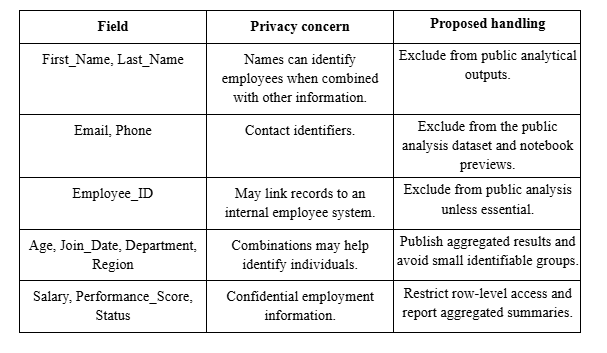

In [22]:
# Create an analytical view without direct identifying columns.
# This reduces exposure but does not guarantee full anonymity.
identifying_columns = [
    "Employee_ID",
    "First_Name",
    "Last_Name",
    "Email",
    "Phone"
]

analysis_person3 = df_person3.drop(
    columns=identifying_columns
).copy()

print("Columns retained in the analytical view:")
print(analysis_person3.columns.tolist())

# Avoid displaying original.head() or df_person3.head()
# in a public notebook because they contain identifying fields.

Columns retained in the analytical view:
['Age', 'Department_Region', 'Status', 'Join_Date', 'Salary', 'Performance_Score', 'Remote_Work', 'Age_missing_flag', 'Salary_missing_flag', 'Department', 'Region', 'Email_Repeated', 'Phone_Invalid']


### **5.7.1 Privacy Protection Measures and Remaining Risks**

The synthetic dataset contains fields that would identify individuals or reveal sensitive employment information in real HR records. A separate analytical view excludes Employee_ID, First_Name, Last_Name, Email, and Phone, while retaining the missing-value and data-quality flags. Public reporting should use aggregated statistics because combinations of age, department, region, and joining date may enable identification in real employee data, even after direct identifiers are removed. These measures demonstrate privacy-conscious handling; they do not establish that the remaining data is fully anonymous.

### **5.8 Examine Potential Bias and Group Imbalance**

Here we examine the distributions of employees across departments, regions, employment status, remote work arrangements, performance ratings, and recorded ages. These checks help identify underrepresented groups and limitations that may affect the fairness and representativeness of subsequent analysis.

In [23]:
# Use observed ages and retain missing ages as a separate group.
# Do not impute ages for this representation check.
age_groups = original["Age"].apply(
    lambda value: "Missing" if pd.isna(value) else str(int(value))
)

group_data = {
    "Department": df_person3["Department"],
    "Region": df_person3["Region"],
    "Status": df_person3["Status"],
    "Remote_Work": df_person3["Remote_Work"].map({
        True: "Remote",
        False: "Not remote"
    }),
    "Performance_Score": df_person3["Performance_Score"],
    "Age": age_groups
}

for group_name, values in group_data.items():
    counts = values.value_counts(dropna=False)

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": (counts / len(df_person3) * 100).round(2)
    })

    print(f"\n{group_name} distribution:")
    display(summary)


Department distribution:


,Count,Percentage (%)
Department,,
DevOps,189,18.53
Sales,178,17.45
HR,171,16.76
Finance,170,16.67
Admin,166,16.27
Cloud Tech,146,14.31



Region distribution:


,Count,Percentage (%)
Region,,
California,187,18.33
Florida,185,18.14
Nevada,169,16.57
Illinois,165,16.18
New York,161,15.78
Texas,153,15.00



Status distribution:


,Count,Percentage (%)
Status,,
Pending,356,34.90
Active,352,34.51
Inactive,312,30.59


... (2 outputs left out)


Performance_Score distribution:


,Count,Percentage (%)
Performance_Score,,
Good,270,26.47
Average,267,26.18
Excellent,267,26.18
Poor,216,21.18



Age distribution:


,Count,Percentage (%)
Age,,
Missing,211,20.69
40,210,20.59
25,206,20.20
30,205,20.10
35,188,18.43


### **5.8.1 Group Representation and Potential Bias Findings**

Remote work was approximately balanced, with 513 remote employees (50.29%) and 507 non-remote employees (49.71%). Employment status showed moderate variation: Pending accounted for 356 records (34.90%), Active for 352 (34.51%), and Inactive for 312 (30.59%). Department counts ranged from 146 for Cloud Tech to 189 for DevOps, while region counts ranged from 153 for Texas to 187 for California. Performance ratings ranged from 216 Poor ratings (21.18%) to 270 Good ratings (26.47%). These differences describe representation within the dataset; they do not independently demonstrate unfairness.

Age-related analysis has stronger limitations. Observed ages were restricted to 25, 30, 35, and 40, while 211 records (20.69%) had missing ages. Consequently, the dataset cannot support broad conclusions about employees of other ages. Missing ages were retained and flagged rather than imputed. Further checks of age missingness across departments and regions could identify groups with less complete information. Gender and ethnicity were not recorded, so fairness across those attributes cannot be assessed. As this is a synthetic dataset with no established real workforce sampling frame, these distributions should not be treated as representative of an actual employee population.

### **5.9 Visualize Employee Group Distributions**

Here we create labelled charts showing employee counts by department and recorded age, including missing ages as a separate category. These charts highlight differences in group representation and limitations in age coverage and completeness.

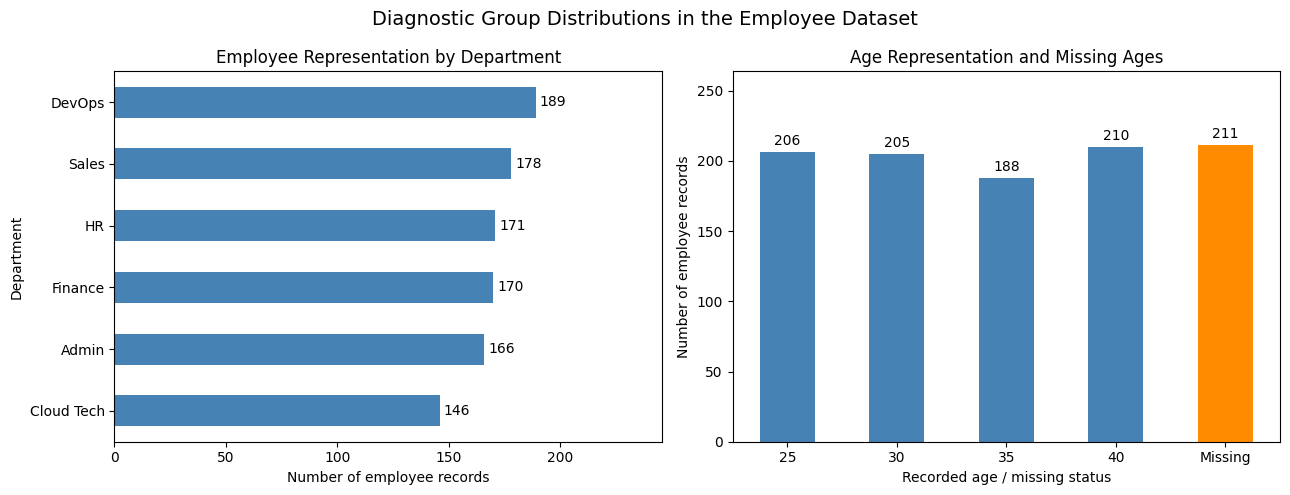

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Department representation.
department_counts = (
    df_person3["Department"].value_counts().sort_values()
)

department_counts.plot.barh(
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Employee Representation by Department")
axes[0].set_xlabel("Number of employee records")
axes[0].set_ylabel("Department")
axes[0].set_xlim(0, department_counts.max() * 1.30)

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Panel 2: Observed ages plus missing ages.
age_counts = age_groups.value_counts().reindex(
    ["25", "30", "35", "40", "Missing"],
    fill_value=0
)

age_counts.plot.bar(
    ax=axes[1],
    color=["steelblue"] * 4 + ["darkorange"],
    rot=0
)

axes[1].set_title("Age Representation and Missing Ages")
axes[1].set_xlabel("Recorded age / missing status")
axes[1].set_ylabel("Number of employee records")
axes[1].set_ylim(0, age_counts.max() * 1.25)

for container in axes[1].containers:
    axes[1].bar_label(container, padding=3)

fig.suptitle(
    "Diagnostic Group Distributions in the Employee Dataset",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [25]:
# Consolidate all completed cleaning steps.
df_clean = df_person3.copy(deep=True)

print("Final working dataset shape:", df_clean.shape)
print("Analytical view shape:", analysis_person3.shape)

Final working dataset shape: (1020, 18)
Analytical view shape: (1020, 13)


### **5.9.1 Interpretation of Employee Group Distribution Charts**

Department counts range from 146 for Cloud Tech to 189 for DevOps. Observed ages are restricted to 25, 30, 35, and 40, while 211 records (20.69%) have missing ages. Displaying missing ages separately makes the completeness issue visible without imputing values or excluding records. These charts highlight differences in group representation and limitations in age coverage; unequal group counts alone do not establish discriminatory bias.

## **Part 6: Conclusion and Limitations**

### **6.1 Is the Data Fit for the Scenario?**

The dataset is suitable for the educational scenario of profiling synthetic HR records and demonstrating justified data-quality handling. All 1,020 records were retained. No duplicate records or statistical outliers in Age and Salary were detected using the checks performed. Date formats were standardized, department and region were separated, and identifying fields were excluded from a separate analytical view.

- **Age Data (Usable with Limitations)**: Analysis can use the 809 observed ages, while explicitly reporting the 211 missing values (20.69%). However, observed ages are restricted to 25, 30, 35, and 40, limiting broader demographic conclusions. Missing ages were retained and flagged rather than imputed.
- **Salary Data (Usable with Care)**: Descriptive analysis can use the 996 observed salaries, with the 24 missing values (2.35%) reported separately. No outliers were detected using the 1.5 × IQR rule, but this does not establish that every salary is accurate. Currency and payment frequency require clarification before meaningful compensation comparisons.
- **Department and Region Data (Suitable for Descriptive Reporting)**: Separating Department_Region produced complete fields for department and regional summaries. However, consistency and completeness do not independently establish accuracy or representativeness.

### **6.2 Remaining Data Limitations**
There are some major issues we cannot fix without getting new data from the company's real database:

**1. Invalid Phone Values:** All 1,020 original phone values begin with a minus sign. Their cause and correct replacements cannot be established from the dataset. They were flagged and replaced with missing values in the working contact field, while the original source values were preserved.

**2. Repeated Email Addresses:** Only 64 unique email addresses appear across 1,020 records, and every address occurs more than once. These repetitions require verification before emails can be treated as unique employee contact identifiers. They do not establish that the employee records are duplicates.

**3. Unresolved Missing Values:** Age and Salary retain their original missing values with tracking flags. This avoids inventing information, but subsequent analyses must report their available sample sizes and acknowledge possible bias from missingness.

**4. Limited Bias Assessment:** Restricted age coverage and the absence of gender and ethnicity prevent a comprehensive demographic fairness assessment. Unequal group counts alone do not demonstrate discrimination.

